# Passo 7 – Teste final (01/2025 a 03/2026)

Rodado **uma única vez**, com tudo congelado nos Passos 1–6. Nenhuma escolha é alterada depois deste notebook.
O período extra (04/2026 a 09/2026) **não** é usado aqui.

**Modelo congelado:** WIN · candle 60 min · janela 36 meses · re-treino trimestral · 17 variáveis (5 lags + forma + volatilidade + volume + contexto do dia) ·
RF(300 árvores, profundidade 4, folha mínima 1%, max_features 0,5) · treinado **sem custo** · opera quando |movimento previsto| > 5 pts.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
import rf_zero as rz
win_1m = rz.carregar("../../dados/WINN_M1/WIN$N_M1.csv")
base, cols = rz.montar_base(win_1m, 60)
fab = lambda n: RandomForestRegressor(n_estimators=300, max_depth=4, min_samples_leaf=0.01,
                                      max_features=0.5, n_jobs=-1, random_state=42)
periodos = {"validação 2024": rz.VALIDACAO, "teste 01/25–03/26": rz.TESTE}
prevs = {nome: rz.walk_forward(base, cols, iv, 36, "QS", fabrica=fab) for nome, iv in periodos.items()}
pd.to_pickle(prevs, "saidas/passo07_previsoes.pkl")
{k: (v.index.min(), v.index.max(), len(v)) for k, v in prevs.items()}

{'validação 2024': (Timestamp('2024-01-02 09:00:00'),
  Timestamp('2024-12-30 16:00:00'),
  2004),
 'teste 01/25–03/26': (Timestamp('2025-01-02 09:00:00'),
  Timestamp('2026-03-31 16:00:00'),
  2480)}

In [2]:
rng = np.random.default_rng(42)
def aplicar_regra(d, custo=rz.CUSTO_PTS):
    pts = rz.prev_pontos(d)
    dirc = np.sign(pts).where(pts.abs() > rz.CUSTO_PTS, 0)
    op = dirc != 0
    res = pd.Series(rz.resultado_operacoes(dirc.values, d["mov_prox"].values, custo), index=d.index[op.values])
    return res, d["mov_prox"].values[op.values]

linhas, resultados = {}, {}
for nome, d in prevs.items():
    res, mov = aplicar_regra(d)
    r = rz.resumo_ops(res.values, res.index)
    sims = (rng.choice([-1, 1], size=(2000, len(mov))) * mov).mean(axis=1) - rz.CUSTO_PTS
    r["p vs aleatório"] = (sims >= res.mean()).mean()
    s = rz.avaliar(d["prev"].values, d)
    r["R² %"] = s["R² vs naive %"]; r["acerto direção (todos) %"] = s["acerto direção %"]
    r["ganho bruto pts/op (regra)"] = res.mean() + rz.CUSTO_PTS
    linhas[nome] = r; resultados[nome] = res
tab = pd.DataFrame(linhas).T
tab.to_csv("saidas/passo07_resultado.csv")
tab.round(2).T

,validação 2024,teste 01/25–03/26
n_ops,1532.00,2114.00
esperança pts/op,14.06,2.98
t,1.76,0.29
acerto %,51.50,49.53
trimestres +,4.00,2.00
total pts,21535.00,6300.00
total R$ (1 contrato),4307.00,1260.00
drawdown máx pts,5950.00,21310.00
p vs aleatório,0.01,0.20
R² %,0.38,-0.70


**Referência – modelo anterior da frente** (RF classificador 3 classes, 1 min, rodado no mesmo teste em 11/11): **−4,82 pts/op** operando sempre; ganho bruto +0,18 pts/op.

In [3]:
# por trimestre
pd.DataFrame({k: v.groupby(v.index.to_period("Q")).agg(["mean", "count", "sum"]).rename(
    columns={"mean": "esperança pts/op", "count": "n_ops", "sum": "total pts"}).stack() for k, v in resultados.items()}).unstack().round(1)

validação 2024                  teste 01/25–03/26                 
       esperança pts/op  n_ops total pts  esperança pts/op  n_ops total pts
2024Q1             19.5  327.0    6370.0               NaN    NaN       NaN
2024Q2              7.3  401.0    2940.0               NaN    NaN       NaN
2024Q3              2.1  397.0     815.0               NaN    NaN       NaN
2024Q4             28.0  407.0   11410.0               NaN    NaN       NaN
2025Q1              NaN    NaN       NaN             -10.6  407.0   -4305.0
2025Q2              NaN    NaN       NaN              -3.3  419.0   -1400.0
2025Q3              NaN    NaN       NaN              24.9  424.0   10545.0
2025Q4              NaN    NaN       NaN              22.2  435.0    9640.0
2026Q1              NaN    NaN       NaN             -19.1  429.0   -8180.0

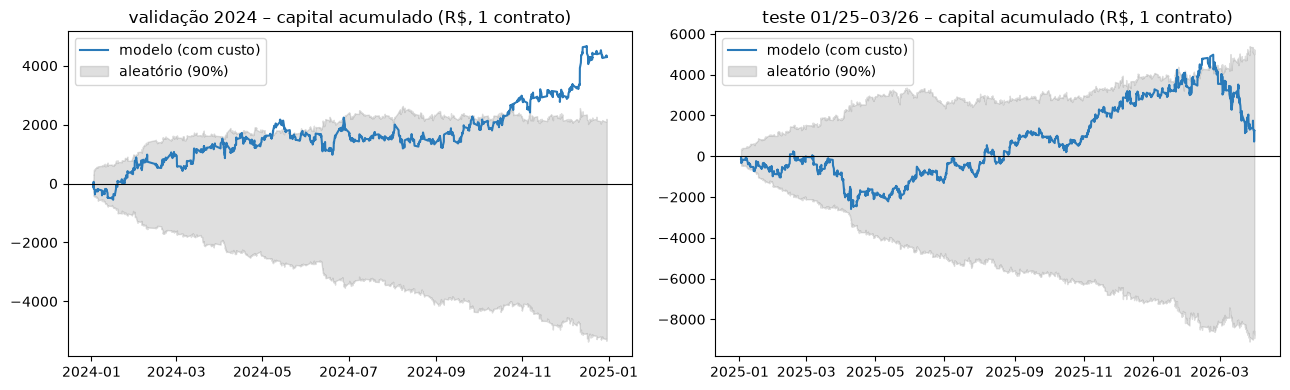

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for a, (nome, res) in zip(axs, resultados.items()):
    cap = res.cumsum() * rz.REAIS_POR_PONTO["WIN"]
    a.plot(cap.index, cap.values, color="#2a7ab9", label="modelo (com custo)")
    # banda de 90% de 200 trajetórias aleatórias nos mesmos candles
    _, mov = aplicar_regra(prevs[nome])
    trajs = np.cumsum(rng.choice([-1, 1], size=(200, len(mov))) * mov - rz.CUSTO_PTS, axis=1) * rz.REAIS_POR_PONTO["WIN"]
    a.fill_between(cap.index, np.percentile(trajs, 5, axis=0), np.percentile(trajs, 95, axis=0), color="gray", alpha=.25, label="aleatório (90%)")
    a.axhline(0, color="k", lw=.8); a.set_title(f"{nome} – capital acumulado (R$, 1 contrato)"); a.legend(loc="upper left")
plt.tight_layout(); plt.savefig("passo07_curva_capital.png", dpi=120); plt.show()

In [5]:
# sensibilidade ao custo no teste
bruto = resultados["teste 01/25–03/26"] + rz.CUSTO_PTS
pd.Series({f"custo {c} pts": bruto.mean() - c for c in [0, 2, 5, 10, 15]}, name="esperança pts/op no teste").round(2).to_frame().T

,custo 0 pts,custo 2 pts,custo 5 pts,custo 10 pts,custo 15 pts
esperança pts/op no teste,7.98,5.98,2.98,-2.02,-7.02


## Conclusões do Passo 7

| | Validação 2024 | **Teste 01/25–03/26** |
|---|---|---|
| Operações | 1.532 | 2.114 |
| Esperança líquida (pts/op) | +14,1 | **+3,0** |
| t | 1,8 | **0,3** |
| Trimestres positivos | 4 de 4 | **2 de 5** |
| Total (1 contrato) | R$ 4.307 | **R$ 1.260** |
| Maior queda acumulada (drawdown) | 5.950 pts | **21.310 pts (R$ 4.262)** |
| p vs aleatório | 0,01 | **0,20** |
| R² | +0,38% | −0,70% |

1. **O resultado positivo da validação não se confirmou com força no teste.** O modelo terminou no positivo (+3,0 pts/op, +R$ 1.260), mas com t = 0,3 e p = 0,20 contra o aleatório: **não dá para distinguir de sorte**.
2. **Instabilidade entre trimestres:** dois trimestres muito bons (3º e 4º de 2025, +25 e +22 pts/op) e três negativos, com o pior no 1º trimestre de 2026 (−19 pts/op). O drawdown de R$ 4,3 mil é maior que o lucro total – um operador real provavelmente teria parado no meio.
3. **Por que caiu da validação para o teste?** Escolhemos entre ~150 configurações olhando um único ano (2024). Mesmo exigindo consistência, parte do +14 da validação era o melhor caso entre muitos – é o efeito esperado de "seleção pelo vencedor". O teste, que nunca participou da escolha, mostra o valor mais realista.
4. **Mesmo assim, é melhor que o modelo anterior** (−4,8 → +3,0 pts/op no mesmo teste), e o ganho bruto (+8,0 pts/op) passa do custo. As decisões que mais explicam a melhora – candle maior, janela longa, árvore rasa e regra "só opera se o previsto pagar o custo" – têm justificativa independente do resultado.
5. **Sensibilidade ao custo:** empata com custo de ~8 pts; com 10 pts já fica negativo (−2,0 pts/op).

Este resultado fica registrado como está; nenhuma escolha é alterada a partir dele.
